# Retraining on the clean data: Task Complexity

**Goal.** Ask the earlier questions again, on the features recomputed through the factor package's cleaning code (see
[ARCHITECTURE.md](../../ARCHITECTURE.md)): which preprocessing and model, how good, and does it meet the criteria. The rules were fixed
before any of this ran in [RETRAIN_PROTOCOL.md](../../RETRAIN_PROTOCOL.md); the decision rules and success criteria are the earlier protocol's own.

**Disclosure.** Each group was a test group once in the earlier experiments, scored on the old features with the same 20 labels. This
notebook scores them again on changed features. Every choice here is made on validation groups only, and the new test result is
reported **beside** the earlier one. It shows the effect of cleaning on the same 20 students, not fresh independent evidence.

**Data.** 144 real student-sprints (20 rated) plus 175 simulated student-sprints, **training only**: never validated, never tested, labels are
estimates from the label model.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("../../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import retrain as R
from core import GROUPS, group_bootstrap, load, make_splits, md_table, metrics, paired_diff_bootstrap
from retrain_configs import CONFIGS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

cfg = CONFIGS["task_complexity"]()
F = cfg.factor()
RES = F.results
d = load(F)
real, sim = d[d.source == "real"], d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
LABEL, ACT = cfg.label, cfg.activity
print(cfg.title, "| real", len(real), "| rated", len(gold), "| simulated (training only)", len(sim))

Task Complexity | real 144 | rated 20 | simulated (training only) 175


## 1. What cleaning changed in the data

In [2]:
old = pd.read_csv(Path("../dataset") / cfg.dataset_file, low_memory=False)
old = old[old.source == "real"].set_index("record_id")
cols = [c for c, _ in cfg.proposal]
rows = []
for c in cols:
    new_v = real.set_index("record_id")[c].astype(float)
    old_v = old[c].astype(float).reindex(new_v.index)
    ok = new_v.notna() & old_v.notna()
    rows.append({"feature": c, "median before": old_v.median(), "median now": new_v.median(),
                 "total now / before": new_v[ok].sum() / old_v[ok].sum() if old_v[ok].sum() else np.nan,
                 "rank agreement": new_v[ok].corr(old_v[ok], method="spearman")})
print("Real student-sprints: the proposal's features before and after cleaning")
display(pd.DataFrame(rows).set_index("feature").round(3))
rows = []
for c in cols:
    for name, frame in (("real", real), ("simulated", sim)):
        x = frame[c].astype(float).dropna()
        rows.append({"feature": c, "group": name, "p10": x.quantile(.1), "median": x.median(), "p90": x.quantile(.9), "missing": frame[c].isna().mean()})
print("Simulated students against real students (clean features)")
pd.DataFrame(rows).set_index(["feature", "group"]).round(3)

Real student-sprints: the proposal's features before and after cleaning


,median before,median now,total now / before,rank agreement
feature,,,,
TC_SP,4.000,4.000,1.000,1.000
TC_SC,2.584,2.584,1.000,1.000
TC_FI,16.000,13.292,0.548,0.851
TC_DR,2.000,2.000,1.050,0.994
TC_CB,5.000,4.333,0.762,0.740


Simulated students against real students (clean features)


p10  median     p90  missing
feature group                                    
TC_SP   real       2.707   4.000   5.333    0.000
        simulated  3.000   5.000   8.000    0.000
TC_SC   real       2.000   2.584   3.078    0.000
        simulated  2.000   3.000   3.500    0.000
TC_FI   real       5.000  13.292  28.880    0.250
        simulated  5.000  10.000  16.000    0.171
TC_DR   real       0.000   2.000  17.885    0.250
        simulated  0.000   1.000   5.300    0.171
TC_CB   real       1.850   4.333   7.275    0.250
        simulated  1.000   2.000   3.000    0.171

## 2. Splits and baselines (validation)

In [3]:
splits = make_splits(d)
splits.to_csv(F.splits, index=False)
role = splits.join(d[["source", "label_source"]], on="record_id")
chk = role.groupby(["outer_test", "inner_val", "role"]).size().unstack(fill_value=0)
assert not ((role.role == "val") & (role.source == "synthetic")).any() and not ((role.role == "test") & (role.source == "synthetic")).any()
print("20 combinations; simulated rows are never in validation or test. Records per role (first rows):")
display(chk.head(8))
base = pd.read_csv(RES / "baseline_predictions.csv")
rows = []
for name, g in base.groupby("name"):
    m = metrics(g.y, g.pred)
    rows.append({"baseline": name, "MAE": m["MAE"], "pearson": m["pearson"], "spearman": m["spearman"], "bias": m["bias"]})
display(pd.DataFrame(rows).set_index("baseline").sort_values("MAE").round(3))

20 combinations; simulated rows are never in validation or test. Records per role (first rows):


role                  test  train  val
outer_test inner_val                  
A          B            71    220   28
           C            71    227   21
           D            71    232   16
           E            71    240    8
B          A            28    220   71
           C            28    270   21
           D            28    275   16
           E            28    283    8

,MAE,pearson,spearman,bias
baseline,,,,
"files involved (log, linear)",0.112,0.089,0.008,0.023
ridge (5 proposal features),0.118,0.202,0.013,0.030
story points (linear),0.120,0.219,0.204,-0.001
mean,0.128,-0.399,-0.394,-0.007
median,0.131,-0.389,-0.411,-0.029
subtasks (linear),0.137,-0.134,-0.216,0.009


## 3. Preprocessing: variants and label sources (Ridge, validation, selection without bias)

In [4]:
tuned = pd.read_csv(RES / "tuning_predictions.csv")
settings = json.load(open(RES / "settings.json"))
tuned.attrs["settings_path"] = str(RES / "settings.json")
rows = []
for (variant, lab, weight), g in tuned[tuned.model == "Ridge"].groupby(["variant", "lab", "weight"]):
    p, _ = R.bias_free(g)
    m = metrics(p.y, p.pred)
    rows.append({"variant": variant, "label source": lab, "weight": weight, "MAE": m["MAE"], "pearson": m["pearson"]})
prep = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
prep.round(3)

,variant,label source,weight,MAE,pearson
0,proposal 5 (log counts),rated + propagated (real + synthetic),0.3,0.116,0.184
1,proposal 5 (log counts),rated + propagated (real + synthetic),1.0,0.116,0.194
2,proposal 5 (log counts),rated only,1.0,0.117,0.127
3,proposal 5 (log counts),rated + propagated (real),0.3,0.120,-0.021
4,proposal 5 (log counts),rated + propagated (real),1.0,0.122,-0.084


## 4. Ridge, Random Forest and Gradient Boosting, tuned, compared without selection bias

In [5]:
choice, table, pools, picks = R.decide(cfg, tuned, base, d, RES)
table.round(3)

,model,variant,MAE,bias,pearson,spearman
0,"Ridge (rated only, LOO alpha)",proposal,0.118,0.030,0.202,0.013
1,Ridge,proposal 5 (log counts),0.119,0.018,0.098,-0.006
2,Gradient Boosting,proposal 5 (log counts),0.128,0.008,-0.168,-0.232
3,Random Forest,proposal 5 (log counts),0.130,0.015,-0.185,-0.268


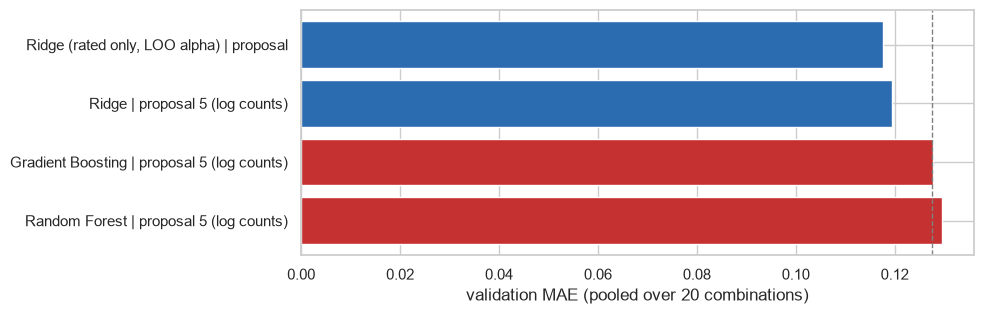

In [6]:
fig, ax = plt.subplots(figsize=(10, 0.45 * len(table) + 1.5))
labels = table.model + " | " + table.variant
ax.barh(labels[::-1], table.MAE[::-1], color=["#c53030" if "Forest" in l or "Boosting" in l else "#2b6cb0" for l in labels[::-1]])
for name, g in base.groupby("name"):
    if name in ("mean",):
        ax.axvline(metrics(g.y, g.pred)["MAE"], color="grey", ls="--", lw=1)
ax.set_xlabel("validation MAE (pooled over 20 combinations)")
fig.tight_layout(); plt.show()

## 5. The rule for keeping a complex model

In [7]:
rule = choice["rule"]
print(f"best Ridge-type model : {rule['ridge']}  (MAE {choice['ridge_best']['MAE']:.3f})")
print(f"best tree model       : {rule['complex']}  (MAE {choice['complex_best']['MAE']:.3f})")
print(f"gain {rule['gain_mae']:+.3f} MAE, 95% interval {rule['ci'][0]:+.3f} to {rule['ci'][1]:+.3f}, better in {rule['folds_better']} of 5 folds")
chosen_name = choice["complex_best"]["model"] if rule["passes_1_3"] else choice["ridge_best"]["model"]
chosen_variant = choice["complex_best"]["variant"] if rule["passes_1_3"] else choice["ridge_best"]["variant"]

print("\nmodel for the final test:", chosen_name, "|", chosen_variant)
json.dump({**choice, "chosen": [chosen_name, chosen_variant]}, open(RES / "model_choice.json", "w"), indent=1, default=float)

best Ridge-type model : Ridge (rated only, LOO alpha) | proposal  (MAE 0.118)
best tree model       : Gradient Boosting | proposal 5 (log counts)  (MAE 0.128)
gain -0.010 MAE, 95% interval -0.019 to +0.000, better in 2 of 5 folds

model for the final test: Ridge (rated only, LOO alpha) | proposal


## 6. Final test, scored once

In [8]:
final, fits = R.final_test(cfg, d, chosen_name, chosen_variant, tuned, settings)
final.to_csv(RES / "final_test_predictions_unguarded.csv", index=False)
MAIN = f"{chosen_name} | {chosen_variant}"

fold_info = pd.DataFrame({o: fits[(chosen_name, chosen_variant, o)][2] for o in GROUPS}).T
display(fold_info)
print(len(final[final.name == MAIN]), "test predictions from", len(GROUPS), "models, each made by a model that never saw that student")

,alpha,label_config
A,0.031623,rated only
B,10.0,rated only
C,0.031623,rated only
D,0.01,rated only
E,0.1,rated only


20 test predictions from 5 models, each made by a model that never saw that student


In [9]:
crit, m = R.criteria_table(cfg, final, MAIN, d)
crit.to_csv(RES / "final_test_criteria.csv", index=False)
display(crit.round(3))

,criterion,value,minimum,target,verdict,note
0,MAE / mean-guess MAE,0.962601,<= 0.8,<= 0.65,NOT MET,"MAE 0.119, 95% interval 0.059-0.195"
1,Pearson and Spearman,0.311 / 0.090,>= 0.5 both,>= 0.7 / 0.7,NOT MET,
2,Beats mean,gain +0.005 (+4%),interval of the gain excludes 0,>= 20% lower,NOT MET,95% interval -0.027 to +0.034
3,Bias,0.034103,within +-0.05,within +-0.03,minimum met,
4,Calibration slope,0.404891,0.5-1.5,0.8-1.2,NOT MET,
5,Rubric bands within one,0.95,>= 85%,>= 90%,target met,exact 45%


,MAE,pearson,spearman,bias
model,,,,
"files involved (log, linear)",0.110,0.108,0.057,0.025
story points (linear),0.118,0.239,0.177,-0.000
"Ridge (rated only, LOO alpha) | proposal",0.119,0.311,0.090,0.034
median,0.120,-0.515,-0.559,-0.017
mean,0.124,-0.622,-0.529,-0.006
subtasks (linear),0.133,-0.175,-0.186,0.009


outer_test,A,B,C,D,E
n,7.000,4.00,4.000,3.000,2.000
MAE,0.099,0.11,0.259,0.056,0.024


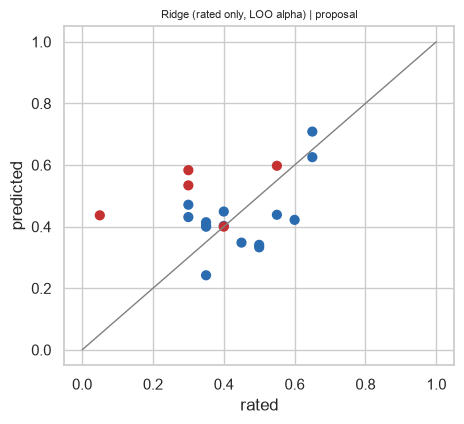

In [10]:
rows = []
for name, g in final.groupby("name"):
    mm = metrics(g.y, g.pred)
    rows.append({"model": name, "MAE": mm["MAE"], "pearson": mm["pearson"], "spearman": mm["spearman"], "bias": mm["bias"]})
display(pd.DataFrame(rows).set_index("model").sort_values("MAE").round(3))
pf = final[final.name == MAIN].assign(err=lambda x: (x.pred - x.y).abs())
display(pf.groupby("outer_test").agg(n=("err", "size"), MAE=("err", "mean")).round(3).T)
f = final[final.name == MAIN]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(f.y, f.pred, c=np.where(f.activity > 0, "#2b6cb0", "#c53030"), s=40)
ax.plot([0, 1], [0, 1], color="grey", lw=1)
ax.set_xlabel("rated"); ax.set_ylabel("predicted"); ax.set_title(MAIN, fontsize=8)
fig.tight_layout(); plt.show()

## 7. Beside the earlier result (old features, same 20 students)

In [11]:
oldp = pd.read_csv(Path("../training/results/final_test_predictions.csv"))
mo, mn = metrics(oldp.y, oldp.pred), metrics(f.y, f.pred)
cmp = pd.DataFrame({"earlier (old features)": mo, "now (clean features)": mn}).loc[["n", "MAE", "RMSE", "bias", "pearson", "spearman", "calib_slope", "band_within_1", "band_exact"]]
display(cmp.round(3))
oldc = pd.read_csv(Path("../training/results/final_test_criteria.csv"))
print("Earlier criteria table (old features):")
display(oldc)

,earlier (old features),now (clean features)
n,20.000,20.000
MAE,0.116,0.119
RMSE,0.150,0.153
bias,0.015,0.034
pearson,0.078,0.311
spearman,0.003,0.090
calib_slope,0.183,0.405
band_within_1,0.950,0.950
band_exact,0.450,0.450


Earlier criteria table (old features):


,criterion,result,minimum (works),target,meets minimum,meets target
0,MAE / MAE of always predicting the mean,0.94 (0.116 / 0.124),<= 0.8,<= 0.65,False,False
1,Pearson,0.078,>= 0.5,>= 0.7,False,False
2,Spearman,0.003,>= 0.5,>= 0.7,False,False
3,Beats always predicting the mean,gain +0.008 (95% CI -0.014 to 0.027),interval excludes 0,and >= 20% lower MAE,False,False
4,Bias,+0.015,within +-0.05,within +-0.03,True,True
5,Calibration slope,0.18,0.5 - 1.5,0.8 - 1.2,False,False
6,Rubric bands within one,95%,>= 85%,>= 90%,True,True


## 8. Reading the results

_Reading of the results: written after the run._